In [1]:
!pip install pingouin


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg

from IPython.display import display

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

In [7]:
df = pd.read_csv("../Data/responses_completo.tsv", sep="\t")


#EDA

In [8]:
variables = [
    "disfrute",
    "competencia",
    "dificultad",
    "ajuste_reto",
    "variedad",
    "rejugar"
]

nombres_variables = {
    "disfrute": "Disfrute",
    "competencia": "Competencia percibida",
    "dificultad": "Dificultad percibida",
    "ajuste_reto": "Ajuste del reto",
    "variedad": "Variedad",
    "rejugar": "Intención de rejugar"
}

condiciones = {
    "H": "Humano",
    "N": "LLM sin telemetría",
    "P": "LLM con telemetría"
}

df["condicion"] = df["level_type"].map(condiciones)

orden = [
    "Humano",
    "LLM sin telemetría",
    "LLM con telemetría"
]

df_promedios = (
    df.groupby(["id", "condicion"], as_index=False)[variables]
      .mean()
)

display(df_promedios.head())

,id,condicion,disfrute,competencia,dificultad,ajuste_reto,variedad,rejugar
0,20261020_130429_S2,Humano,1.0,2.5,-1.5,1.0,1.0,1.0
1,20261020_130429_S2,LLM con telemetría,0.0,0.5,1.5,0.5,2.0,1.0
2,20261020_130429_S2,LLM sin telemetría,-2.5,-2.0,2.5,-2.5,-2.5,-2.5
3,20261020_130434_S5,Humano,0.5,-0.5,-0.5,1.5,0.5,-0.5
4,20261020_130434_S5,LLM con telemetría,0.5,0.0,0.5,2.0,1.5,2.0


In [20]:
estadisticas = (
    df.groupby("condicion")[variables]
      .agg(["mean", "median", "std", "min", "max"])
      .round(3)
)

display(estadisticas)

disfrute                       competencia                       dificultad                       ajuste_reto                       variedad                       rejugar         \
                       mean median    std min max        mean median    std min max       mean median    std min max        mean median    std min max     mean median    std min max    mean median   
condicion                                                                                                                                                                                              
Humano                1.333    1.0  1.239  -3   3       1.542    1.0  1.215  -1   3     -0.375    0.0  1.173  -2   2       1.000    1.0  1.103  -2   3    1.083    1.0  1.381  -3   3   1.292    1.0   
LLM con telemetría   -0.042    0.5  1.989  -3   3      -0.208   -0.5  2.105  -3   3      0.833    1.0  1.736  -3   3      -0.250    0.0  2.132  -3   3    0.000    1.0  2.043  -3   3  -0.167    1.0   
LLM sin telemetría    0.208    1.0  2.021  -3   3      -0.125    0.5  2.173  -3   3      1.042    1.0  1.398  -2   3      -0.083    0.5  1.886  -3   3    0.500    1.5  2.147  -3   3   0.167    1.0   

                                   
                      std min max  
condicion                          
Humano              1.459  -3   3  
LLM con telemetría  2.239  -3   3  
LLM sin telemetría  1.810  -3   3

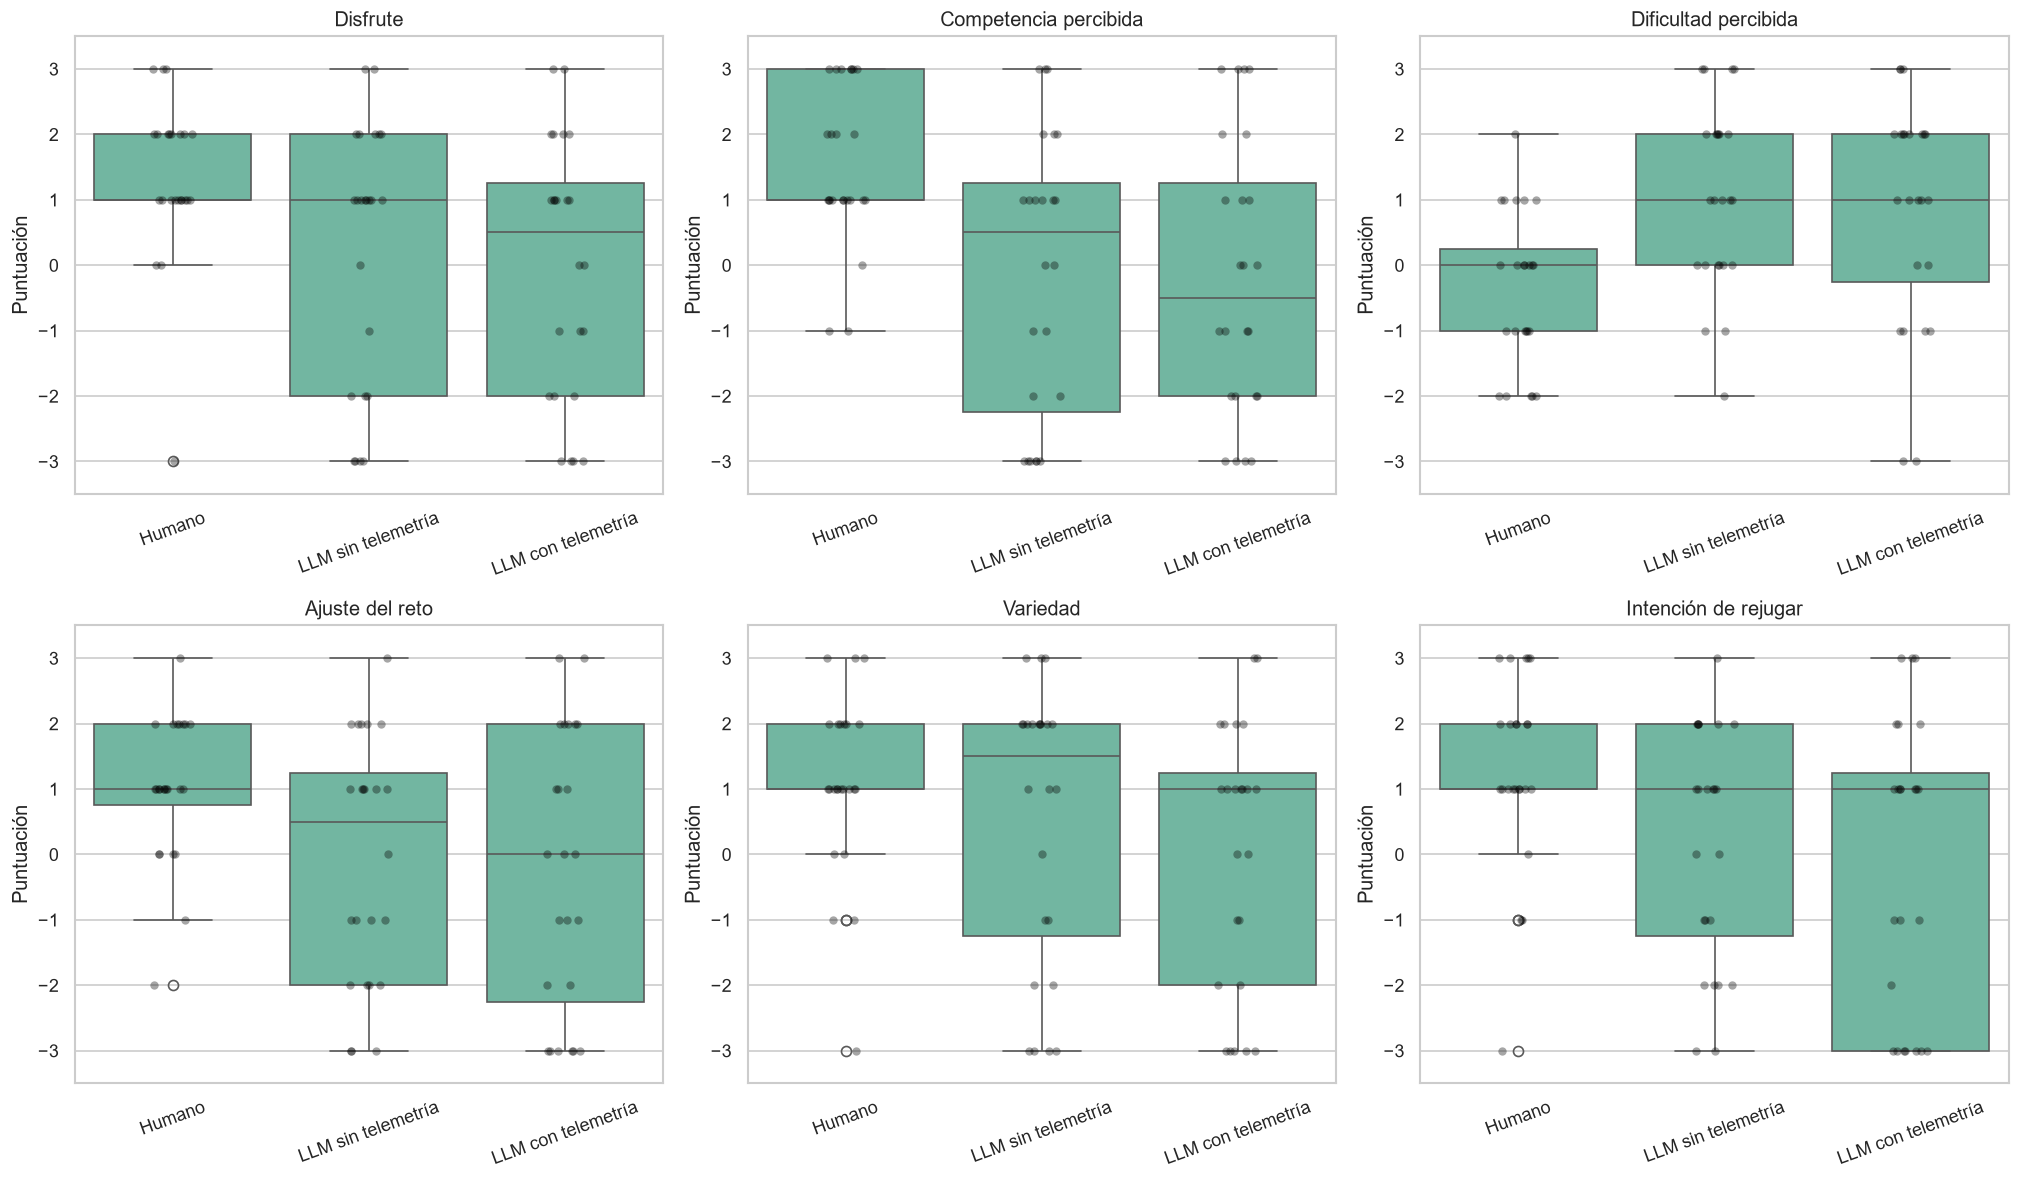

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, variable in zip(axes.flat, variables):
    sns.boxplot(
        data=df,
        x="condicion",
        y=variable,
        order=orden,
        ax=ax
    )

    sns.stripplot(
        data=df,
        x="condicion",
        y=variable,
        order=orden,
        color="black",
        alpha=0.35,
        jitter=True,
        ax=ax
    )

    ax.set_title(nombres_variables[variable])
    ax.set_xlabel("")
    ax.set_ylabel("Puntuación")
    ax.set_ylim(-3.5, 3.5)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

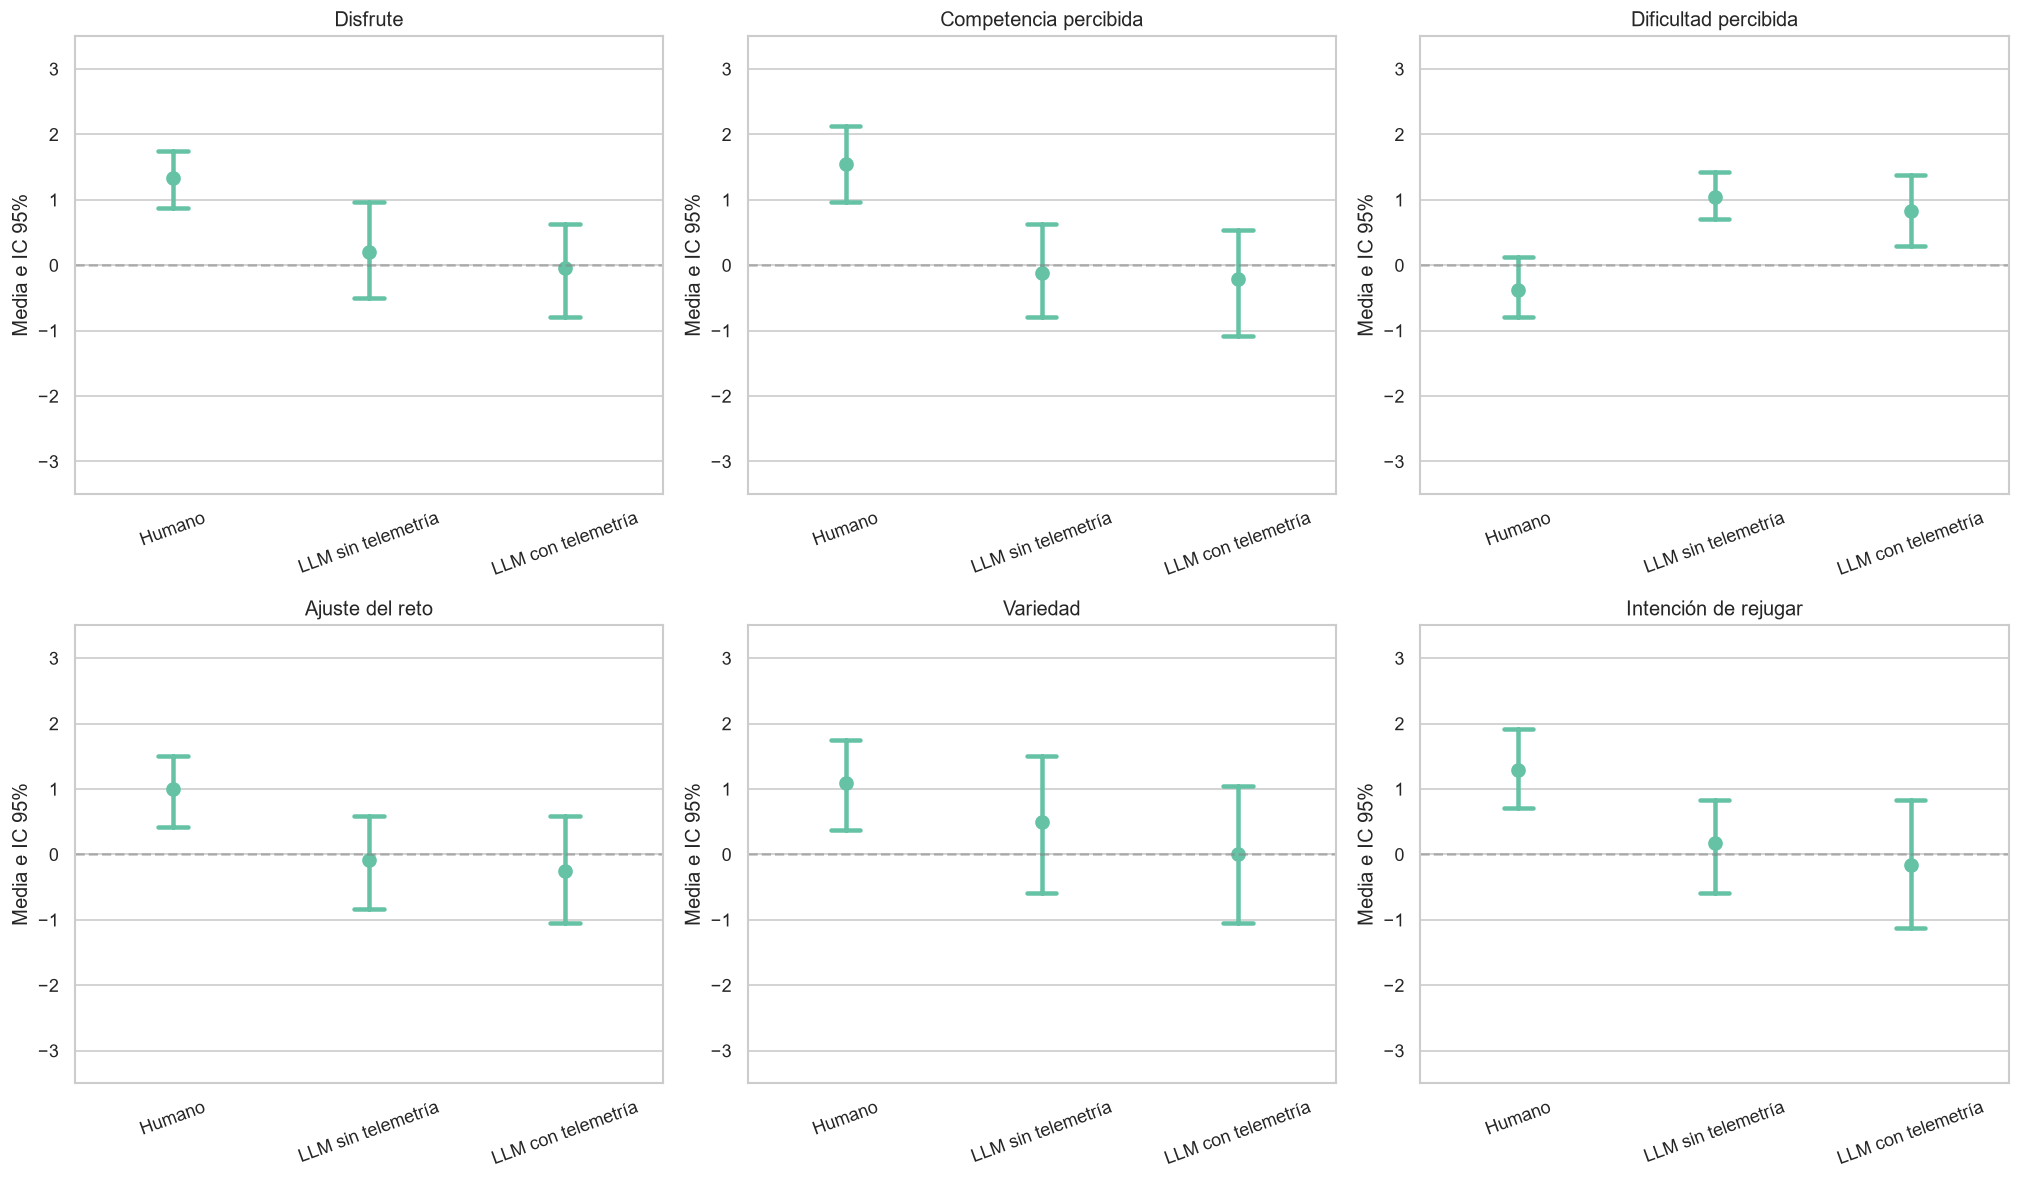

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, variable in zip(axes.flat, variables):
    sns.pointplot(
        data=df_promedios,
        x="condicion",
        y=variable,
        order=orden,
        errorbar=("ci", 95),
        capsize=0.15,
        markers="o",
        linestyles="none",
        ax=ax
    )

    ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
    ax.set_title(nombres_variables[variable])
    ax.set_xlabel("")
    ax.set_ylabel("Media e IC 95%")
    ax.set_ylim(-3.5, 3.5)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

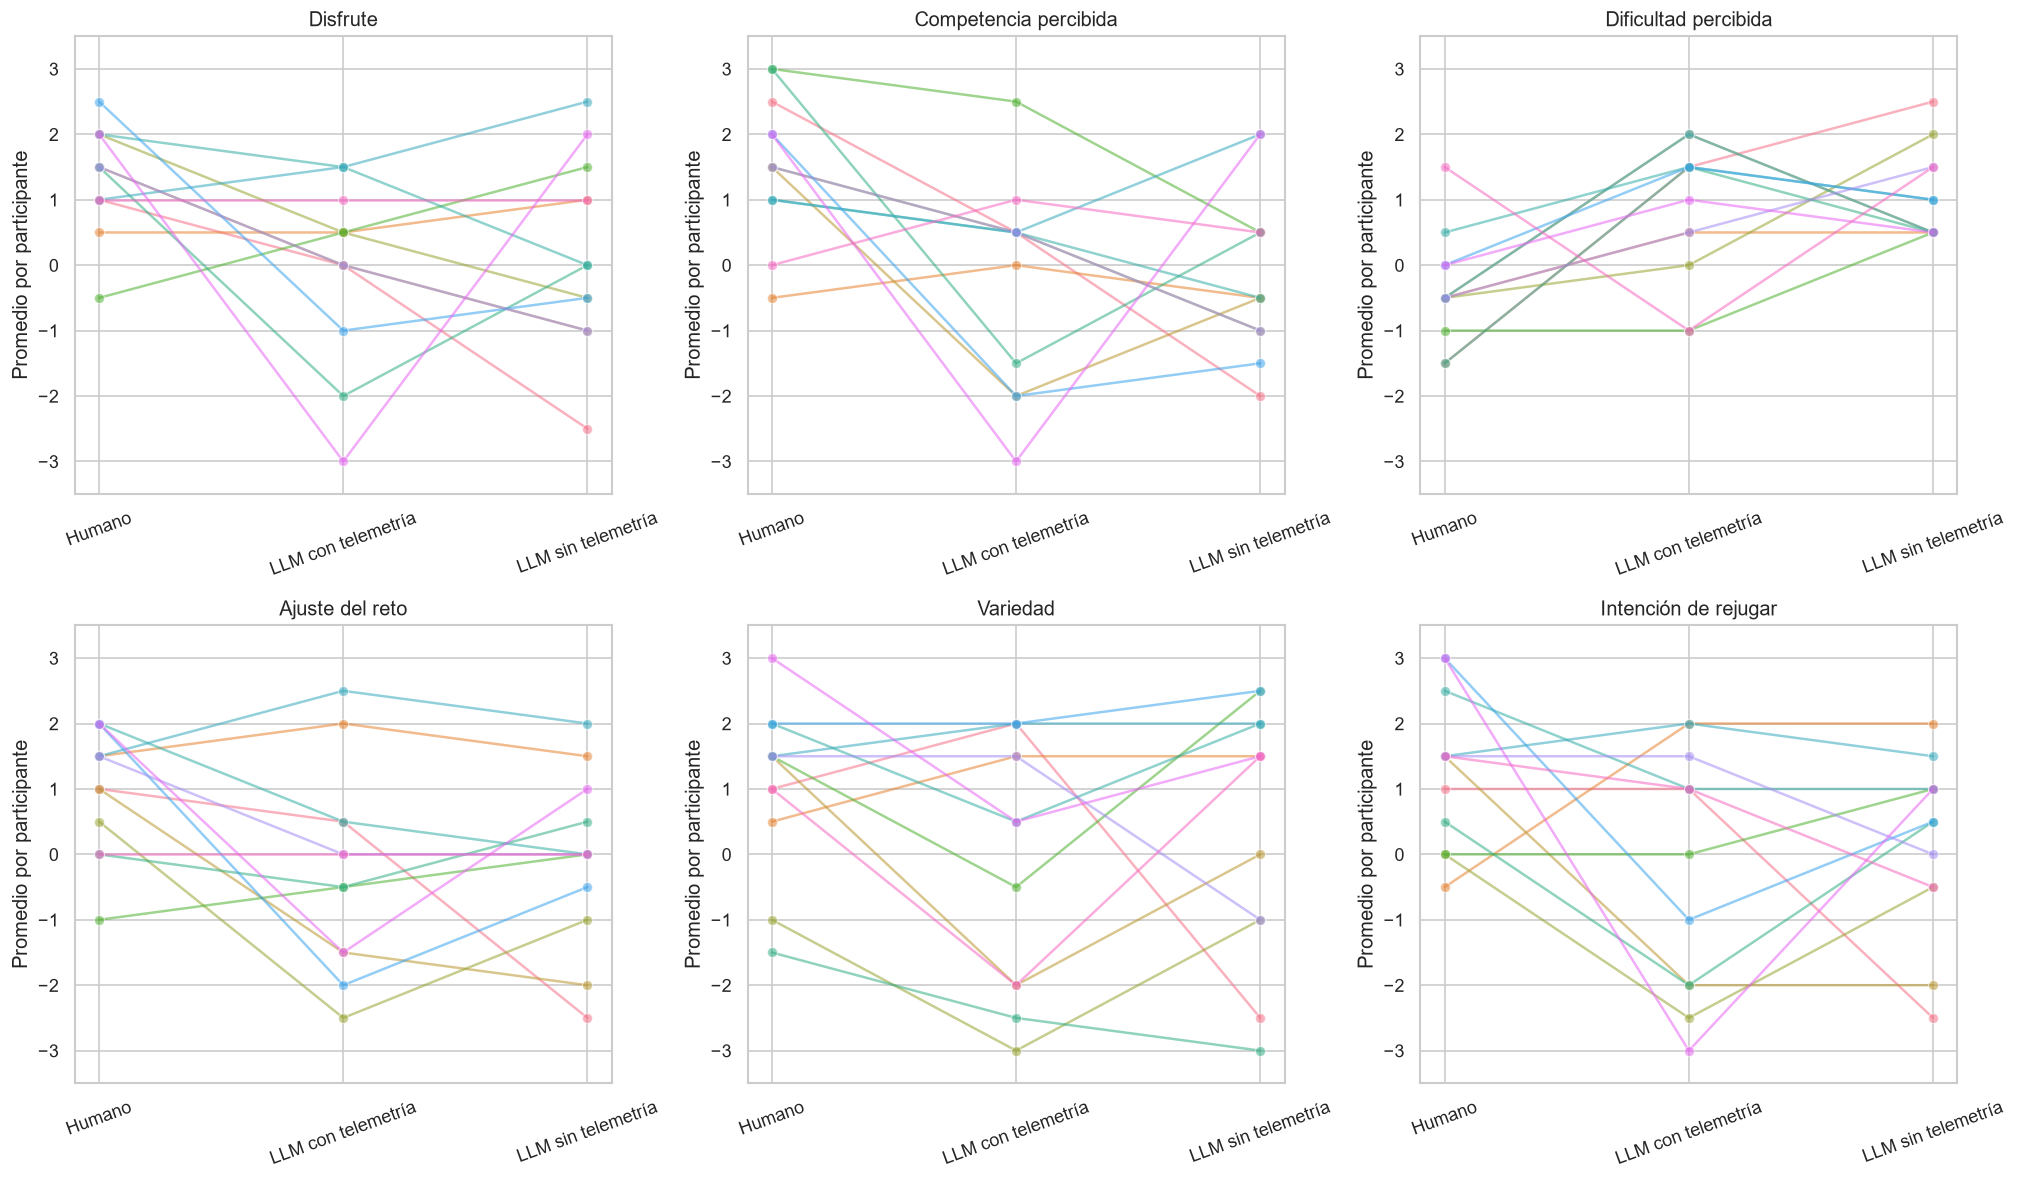

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, variable in zip(axes.flat, variables):

    sns.lineplot(
        data=df_promedios,
        x="condicion",
        y=variable,
        hue="id",
        units="id",
        estimator=None,
        marker="o",
        alpha=0.55,
        legend=False,
        sort=False,
        ax=ax
    )

    ax.set_title(nombres_variables[variable])
    ax.set_xlabel("")
    ax.set_ylabel("Promedio por participante")
    ax.set_ylim(-3.5, 3.5)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

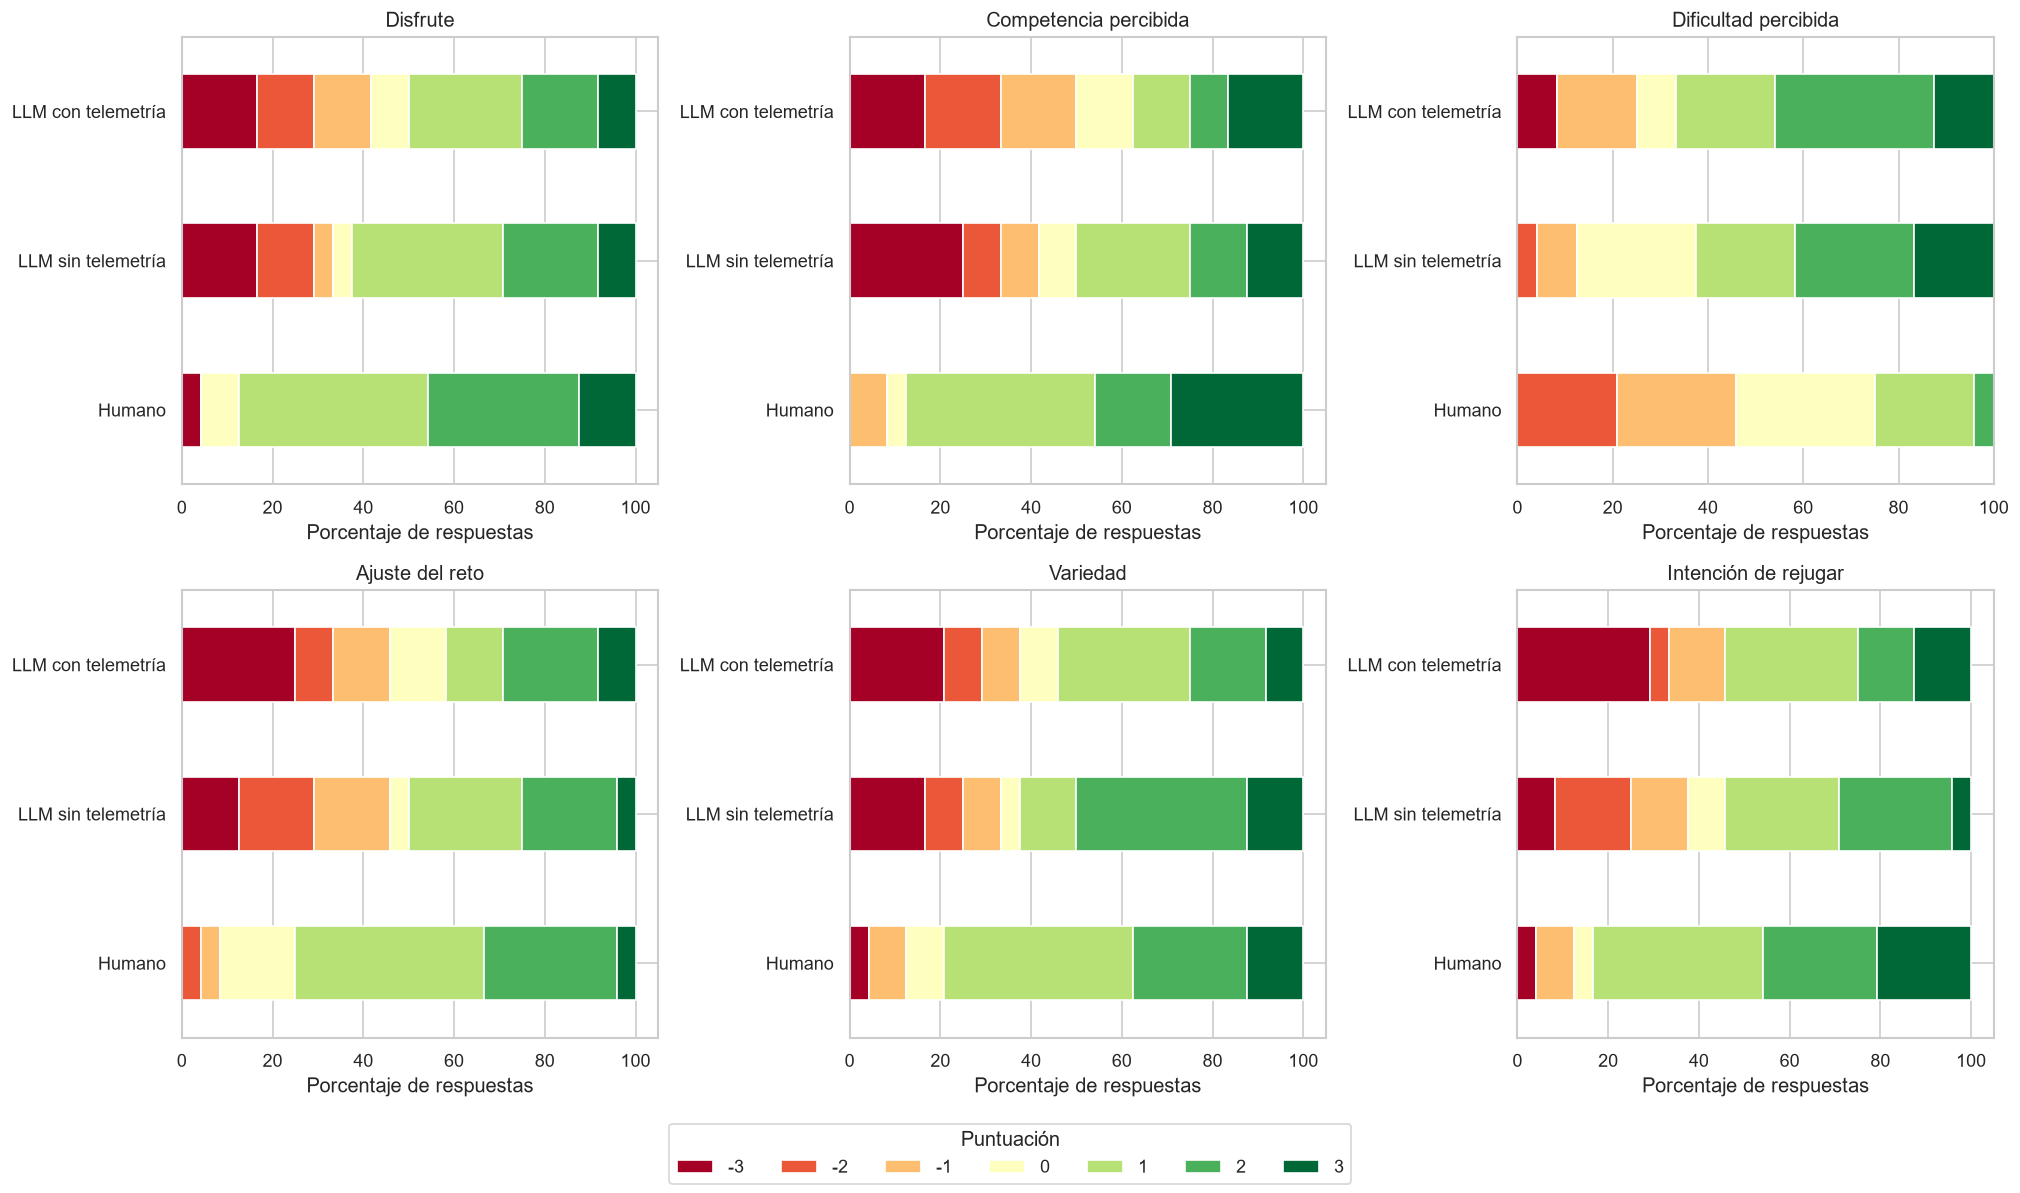

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, variable in zip(axes.flat, variables):

    tabla = pd.crosstab(
        df["condicion"],
        df[variable],
        normalize="index"
    ) * 100

    tabla = tabla.reindex(
        index=orden,
        columns=range(-3, 4),
        fill_value=0
    )

    tabla.plot(
        kind="barh",
        stacked=True,
        ax=ax,
        colormap="RdYlGn",
        legend=False
    )

    ax.set_title(nombres_variables[variable])
    ax.set_xlabel("Porcentaje de respuestas")
    ax.set_ylabel("")

handles, labels = axes.flat[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Puntuación",
    loc="lower center",
    ncol=7
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

## Prueba de normalidad (Shapiro-Wilk)

Antes de elegir/afinar el modelo estadístico conviene revisar si, dentro de
cada condición, la distribución de cada variable se aproxima a una normal.
Se usa la prueba de **Shapiro-Wilk** (`pg.normality`), aplicada sobre las
**72 observaciones individuales** (`df`: las 2 repeticiones de cada
condición sin promediar), ya que el modelo de efectos mixtos usará esas
observaciones completas (con `id` como efecto aleatorio) en lugar de
promediarlas por participante. Promediar antes de evaluar normalidad
reduciría artificialmente la varianza y podría cambiar la conclusión de la
prueba (el mismo problema que ya se identificó para el ANOVA promediado).

H0: los datos de ese grupo provienen de una distribución normal.
Un p-valor < 0.05 indica evidencia de que NO son normales.

In [ ]:
resultados_normalidad = []

for variable in variables:

    normalidad = pg.normality(
        data=df,
        dv=variable,
        group="condicion"
    ).reset_index().rename(columns={"index": "condicion"})

    normalidad["Variable"] = nombres_variables[variable]

    resultados_normalidad.append(normalidad)

tabla_normalidad = pd.concat(resultados_normalidad, ignore_index=True)

tabla_normalidad["Normal (Shapiro-Wilk)"] = tabla_normalidad["normal"].map(
    {True: "Sí", False: "No"}
)

columnas_normalidad = [
    "Variable",
    "condicion",
    "W",
    "pval",
    "Normal (Shapiro-Wilk)"
]

display(
    tabla_normalidad[columnas_normalidad]
        .rename(columns={"condicion": "Condición", "pval": "p-valor"})
        .round(4)
)

n_no_normales = (tabla_normalidad["normal"] == False).sum()
print(f"\nGrupos (variable x condición) que no pasan Shapiro-Wilk (p < 0.05): {n_no_normales} de {len(tabla_normalidad)}")